# Comparative Analysis of Recurrent Neural Networks and Transformer Models for AG News Topic Classification

**MSc Data Science case study** | Python • PyTorch • Hugging Face Transformers • scikit-learn

This notebook trains and compares **five models** on the same four-class news topic task:
Simple RNN, LSTM, GRU, BERT (`bert-base-uncased`) and DistilBERT (`distilbert-base-uncased`).

### How to run this notebook on Kaggle
1. In the right-hand **Settings** panel set **Accelerator → GPU (T4 or P100)** and turn **Internet → On** (needed to download the dataset and pretrained weights).
2. Run the cells from top to bottom (**Run All**).
3. By default the notebook runs on a **small debug subset** so you can check that everything works in a few minutes. To produce your final results, set `USE_FULL_DATASET = True` in the configuration cell of Section 2 and run everything again.

> **Important:** every number, table and plot in this notebook is computed when you run it. Nothing is hardcoded. Text written *before* you run the notebook explains concepts; text produced by code cells reports what was actually measured.

## Section 1: Introduction

### 1.1 Problem statement
Given a short news article (a title and a description), predict which of four topics it belongs to: **World**, **Sports**, **Business** or **Sci/Tech**. This is a **multi-class text classification** problem: each article has exactly one correct label.

### 1.2 Why is news topic classification useful?
- **Organising content:** news websites and apps can automatically file articles under the right section.
- **Personalisation:** recommending articles that match what a reader usually reads.
- **Monitoring and search:** companies and analysts can filter large streams of news (for example, only Business news about their industry).
- **Foundation for other NLP tasks:** topic labels are often used as features for summarisation, trend detection and alerting systems.

### 1.3 Objectives
1. Build a reproducible pipeline for AG News using the official train/test split plus a stratified validation split.
2. Implement three recurrent models (Simple RNN, LSTM, GRU) trained **from scratch**, and two Transformer models (BERT, DistilBERT) **fine-tuned** from pretrained weights.
3. Evaluate all five with the same metrics (accuracy, macro precision, macro recall, macro F1), plus training time, inference time and parameter count.
4. Interpret the results using confusion matrices and training curves.

### 1.4 Research questions
- **RQ1:** Do pretrained Transformers (BERT, DistilBERT) classify AG News more accurately than recurrent models trained from scratch?
- **RQ2:** Among Simple RNN, LSTM and GRU, does the gating mechanism (LSTM/GRU) help compared with a plain RNN?
- **RQ3:** How much extra computational cost (training time, inference time, parameters) do Transformers need for any accuracy gain?
- **RQ4:** Does DistilBERT (a smaller, distilled version of BERT) give a better accuracy-versus-cost trade-off than BERT?

### 1.5 Why compare recurrent and Transformer architectures?
Recurrent networks read text **one word at a time** and keep a memory (hidden state) of what they have read. Transformers use **self-attention** to let every word look at every other word at once, and they come **pretrained** on huge text collections. Comparing them shows the practical value of (a) attention-based architectures and (b) transfer learning, and what that costs in compute.

### 1.6 Training from scratch vs fine-tuning a pretrained Transformer

| | Recurrent models (RNN/LSTM/GRU) here | BERT / DistilBERT here |
|---|---|---|
| Starting weights | Random numbers (the embedding layer is also random) | Weights already trained on large corpora (language knowledge) |
| What training does | Learns word meanings *and* the classification task from only the AG News training data | Adjusts existing knowledge slightly for this task (**fine-tuning**) plus a new, randomly initialised classification layer |
| Vocabulary | Our own word-level vocabulary built from the training split | The model's own pretrained WordPiece tokenizer and vocabulary |
| Training settings | Larger learning rate (2e-3), small batches, learned from scratch | Very small learning rate (2e-5) so pretrained knowledge is only gently adjusted |
| Epochs in this notebook | 5 | 5 (same) |
| Size | Small (a few million parameters, mostly the embedding table) | Large (about 66 million for DistilBERT, 110 million for BERT) |

This difference means the comparison is **not a pure architecture comparison**: Transformers also benefit from pretraining. Section 15 discusses this limitation.

## Section 2: Environment Setup

### 2.1 Import libraries
**What this code does:** it checks that the libraries we need are available (installing `datasets`, `transformers` or `scikit-learn` only if they are missing; Kaggle normally already has them), then imports everything used in the notebook.

In [ ]:
import os, sys, time, json, random, re, gc, copy, warnings, importlib, subprocess, textwrap
from collections import Counter
warnings.filterwarnings("ignore")

def ensure(pip_name, import_name=None):
    # Install a package only if it cannot be imported.
    try:
        importlib.import_module(import_name or pip_name)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])

ensure("datasets")
ensure("transformers")
ensure("scikit-learn", "sklearn")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

import datasets as hf_datasets
import transformers
from datasets import load_dataset
from transformers import (AutoTokenizer, BertForSequenceClassification,
                          DistilBertForSequenceClassification,
                          get_linear_schedule_with_warmup)
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()      # hide the harmless "classifier weights newly initialized" warning

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

print("Libraries imported.")
print(f"torch {torch.__version__} | transformers {transformers.__version__} | datasets {hf_datasets.__version__} | sklearn {sklearn.__version__}")

Libraries imported.
torch 2.11.0+cu130 | transformers 5.20.2 | datasets 4.8.5 | sklearn 1.6.1


### 2.2 Experiment configuration (the important switches)
**What this code does:** it collects every setting in one place. The most important one is `USE_FULL_DATASET`:
- `False` (default) → a small stratified subset, for quick debugging.
- `True` → the full AG News data (120,000 training and 7,600 test articles) for your final results.

**Same epochs for every model:** all five models are trained for exactly `EPOCHS = 5` epochs, with the same learning-rate schedule type (linear warm-up then decay) and the same best-epoch rule (the weights from the epoch with the lowest *validation loss* are used for testing). There is no early stopping, so no model gets fewer epochs than another.

**Overfitting controls:** dropout (0.5 for the recurrent models, extra classifier dropout for the Transformers), weight decay, gradient clipping, learning-rate decay, and restoring the epoch with the lowest validation loss.

Batch sizes were chosen so that BERT fits on a 16 GB Kaggle GPU using mixed precision (fp16). If the GPU still runs out of memory, the training function automatically halves the batch size and retries (Section 5.4).

In [ ]:
# ======================= MAIN SWITCH =======================
USE_FULL_DATASET = False     # False = small debug subset, True = full AG News (final results)
# ===========================================================

SEED = 42
VAL_FRACTION = 0.10          # share of the official training set kept for validation
DEBUG_TRAIN_SIZE = 8000      # used only when USE_FULL_DATASET = False
DEBUG_TEST_SIZE = 2000

# --- Recurrent models: identical settings for RNN, LSTM and GRU (fair comparison) ---
MAX_VOCAB_SIZE = 20000
MIN_WORD_FREQ = 3
RNN_MAX_LEN = 64             # words per article (longer articles are truncated)
EMBED_DIM = 128
HIDDEN_DIM = 128             # per direction (the recurrent layer is bidirectional)
DROPOUT = 0.5                # dropout on the embeddings and before the classifier (reduces overfitting)
RNN_LR = 2e-3
RNN_WEIGHT_DECAY = 0.01
RNN_BATCH_SIZE = 64

# --- Transformer models: identical settings for BERT and DistilBERT ---
TR_MAX_LEN = 128             # sub-word tokens per article
TR_LR = 2e-5
TR_BATCH_SIZE = 32
TR_WEIGHT_DECAY = 0.01
TR_CLASSIFIER_DROPOUT = 0.2  # extra dropout before the new classification layer (reduces overfitting)

EVAL_BATCH_SIZE = 128        # same for validation/test of ALL models

EPOCHS = 5                   # SAME number of epochs for ALL five models (fair comparison)
RNN_EPOCHS = TR_EPOCHS = EPOCHS

RESULTS_DIR = "/kaggle/working/results" if os.path.exists("/kaggle/working") else "./results"
os.makedirs(RESULTS_DIR, exist_ok=True)

mode = "FULL DATASET" if USE_FULL_DATASET else f"DEBUG SUBSET ({DEBUG_TRAIN_SIZE} train / {DEBUG_TEST_SIZE} test)"
print("Run mode      :", mode)
print("Epochs (all 5 models):", EPOCHS)
print("Results folder:", RESULTS_DIR)
if not USE_FULL_DATASET:
    print("\nNOTE: debug results are NOT final. Set USE_FULL_DATASET = True and re-run for your report.")

Run mode      : DEBUG SUBSET (8000 train / 2000 test)
Epochs (all 5 models): 5
Results folder: ./results

NOTE: debug results are NOT final. Set USE_FULL_DATASET = True and re-run for your report.


### 2.3 Reproducibility and GPU detection
**What this code does:** it fixes the random seeds of Python, NumPy and PyTorch so that results are repeatable, and it detects whether a GPU is available. Note: even with seeds, some GPU operations are not perfectly deterministic, so tiny differences between runs are normal.

In [ ]:
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    props = torch.cuda.get_device_properties(0)
    print("GPU name        :", props.name)
    print("GPU memory (GB) :", round(props.total_memory / 1024**3, 1))
    print("GPUs visible    :", torch.cuda.device_count(), "(this notebook uses only GPU 0)")
else:
    print("WARNING: no GPU found. BERT/DistilBERT will be very slow on CPU. Enable a GPU in the Kaggle settings.")

Device: cuda
GPU name        : Tesla T4
GPU memory (GB) : 14.6
GPUs visible    : 1 (this notebook uses only GPU 0)


## Section 3: Dataset Loading

### 3.1 About AG News
AG News is a collection of news articles grouped into four topics. Each record has:
- **`text`** (input feature): the article title and description joined in one string.
- **`label`** (target): an integer from 0 to 3.

| Label id | Class name |
|---|---|
| 0 | World |
| 1 | Sports |
| 2 | Business |
| 3 | Sci/Tech |

We use the **official** splits: `train` (120,000 articles) and `test` (7,600 articles).

**What the next code does:** it downloads the dataset with the Hugging Face `datasets` library, prints its structure, and checks that the label names are in the order we expect.

In [ ]:
raw = load_dataset("fancyzhx/ag_news")
print(raw)
print("\nFeatures:", raw["train"].features)

CLASS_NAMES = raw["train"].features["label"].names
EXPECTED = ["World", "Sports", "Business", "Sci/Tech"]
print("\nLabel names from the dataset:", CLASS_NAMES)
assert CLASS_NAMES == EXPECTED, "Unexpected label order!"
NUM_CLASSES = len(CLASS_NAMES)
id2label = {i: n for i, n in enumerate(CLASS_NAMES)}
label2id = {n: i for i, n in enumerate(CLASS_NAMES)}
print("id2label:", id2label)

README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})

Features: {'text': Value('string'), 'label': ClassLabel(names=['World', 'Sports', 'Business', 'Sci/Tech'])}

Label names from the dataset: ['World', 'Sports', 'Business', 'Sci/Tech']
id2label: {0: 'World', 1: 'Sports', 2: 'Business', 3: 'Sci/Tech'}


### 3.2 Convert to pandas and inspect
**What this code does:** it converts each split to a pandas DataFrame (easy to inspect and split), prints shapes, column names, data types, class counts and a few sample records, and finally verifies the label mapping by printing one example article for every label id.

In [ ]:
train_full_df = raw["train"].to_pandas()
test_full_df = raw["test"].to_pandas()

print("Train shape:", train_full_df.shape, "| Test shape:", test_full_df.shape)
print("Columns    :", list(train_full_df.columns))
print("\nData types:\n", train_full_df.dtypes)

for split_name, df_ in [("TRAIN", train_full_df), ("TEST", test_full_df)]:
    counts = df_["label"].value_counts().sort_index()
    table = pd.DataFrame({"label_id": counts.index,
                          "class": [id2label[i] for i in counts.index],
                          "count": counts.values,
                          "percent": (counts.values / len(df_) * 100).round(2)})
    print(f"\nClass distribution ({split_name}):")
    display(table)

print("\nFirst 3 training records:")
display(train_full_df.head(3))

print("\nLabel mapping check (one example per label id):")
for lid in range(NUM_CLASSES):
    example = train_full_df[train_full_df["label"] == lid]["text"].iloc[0]
    print(f"  label {lid} -> {id2label[lid]:9s} | {example[:110]}...")

Train shape: (120000, 2) | Test shape: (7600, 2)
Columns    : ['text', 'label']

Data types:
 text     object
label     int64
dtype: object

Class distribution (TRAIN):


,label_id,class,count,percent
0,0,World,30000,25.0
1,1,Sports,30000,25.0
2,2,Business,30000,25.0
3,3,Sci/Tech,30000,25.0



Class distribution (TEST):


,label_id,class,count,percent
0,0,World,1900,25.0
1,1,Sports,1900,25.0
2,2,Business,1900,25.0
3,3,Sci/Tech,1900,25.0



First 3 training records:


,text,label
0,Wall St. Bears Claw Back Into the Black (Reute...,2
1,Carlyle Looks Toward Commercial Aerospace (Reu...,2
2,Oil and Economy Cloud Stocks' Outlook (Reuters...,2



Label mapping check (one example per label id):
  label 0 -> World     | Venezuelans Vote Early in Referendum on Chavez Rule (Reuters) Reuters - Venezuelans turned out early\and in la...
  label 1 -> Sports    | Phelps, Thorpe Advance in 200 Freestyle (AP) AP - Michael Phelps took care of qualifying for the Olympic 200-m...
  label 2 -> Business  | Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\band of ult...
  label 3 -> Sci/Tech  | 'Madden,' 'ESPN' Football Score in Different Ways (Reuters) Reuters - Was absenteeism a little high\on Tuesday...


## Section 4: Exploratory Data Analysis (EDA)

EDA means looking at the data before modelling. Here we check (1) whether classes are balanced, (2) how long articles are, (3) what the articles look like, and (4) whether there are missing or duplicated records. EDA uses the full dataset even in debug mode.

### 4.1 Class distribution
**What this code does:** it draws a bar chart of how many articles each class has in the training and test splits. If one class had far more articles than the others, plain accuracy could be misleading, which is one reason we also report macro-averaged metrics.

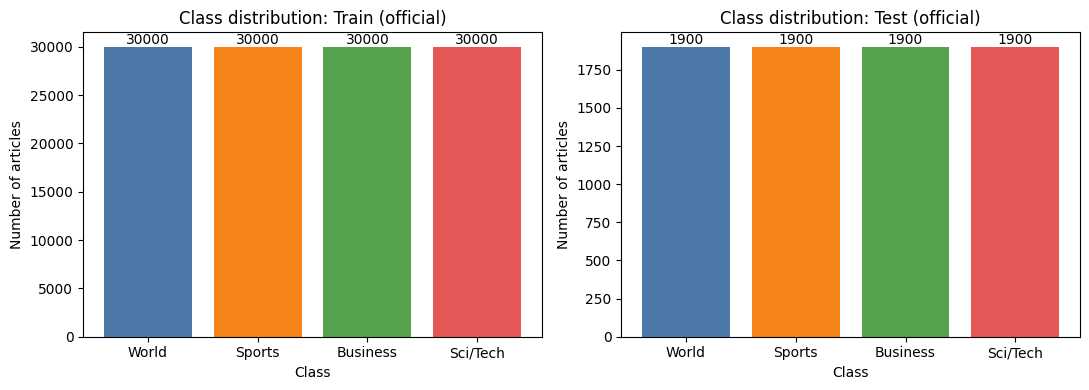

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (title, df_) in zip(axes, [("Train (official)", train_full_df), ("Test (official)", test_full_df)]):
    counts = df_["label"].value_counts().sort_index()
    ax.bar([id2label[i] for i in counts.index], counts.values, color=["#4C78A8", "#F58518", "#54A24B", "#E45756"])
    ax.set_title(f"Class distribution: {title}")
    ax.set_xlabel("Class")
    ax.set_ylabel("Number of articles")
    for i, v in enumerate(counts.values):
        ax.text(i, v, str(v), ha="center", va="bottom")
plt.tight_layout()
plt.show()

### 4.2 Text length in words and in tokens
**What this code does:** it counts the length of each article in two ways:
- **Words:** splitting on spaces (relevant for the recurrent models, which read words).
- **Tokens:** the number of **BERT WordPiece** tokens (relevant for BERT/DistilBERT, which split rare words into smaller pieces). DistilBERT uses the same vocabulary. To save time, token counts use a random sample of 20,000 training articles.

The dashed lines show the maximum lengths we will use (`RNN_MAX_LEN` words and `TR_MAX_LEN` tokens). Articles longer than these are **truncated**; the printed percentages tell you how many articles are affected.

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Words per article:
 count    120000.0
mean         37.8
std          10.1
min           8.0
25%          32.0
50%          37.0
75%          43.0
max         177.0
Name: n_words, dtype: float64

BERT tokens per article (20k sample):
 count    20000.0
mean        53.1
std         19.2
min         18.0
25%         43.0
50%         50.0
75%         59.0
max        379.0
Name: n_tokens, dtype: float64


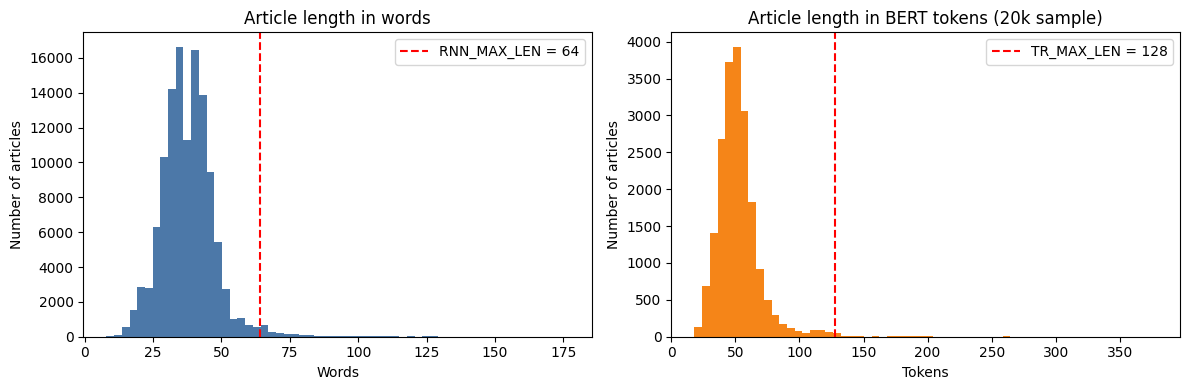

Articles longer than 64 words (truncated for RNN/LSTM/GRU): 1.83%
Articles longer than 128 tokens (truncated for BERT/DistilBERT): 0.74%

Mean words per class:


,mean_words
label,
Business,37.5
Sci/Tech,37.2
Sports,37.8
World,38.9


In [ ]:
bert_tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

train_full_df["n_words"] = train_full_df["text"].str.split().str.len()
sample_df = train_full_df.sample(n=min(20000, len(train_full_df)), random_state=SEED)
sample_tokens = bert_tokenizer(sample_df["text"].tolist(), add_special_tokens=True, truncation=False)["input_ids"]
sample_df = sample_df.assign(n_tokens=[len(x) for x in sample_tokens])

print("Words per article:\n", train_full_df["n_words"].describe().round(1))
print("\nBERT tokens per article (20k sample):\n", sample_df["n_tokens"].describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(train_full_df["n_words"], bins=60, color="#4C78A8")
axes[0].axvline(RNN_MAX_LEN, color="red", linestyle="--", label=f"RNN_MAX_LEN = {RNN_MAX_LEN}")
axes[0].set_title("Article length in words")
axes[0].set_xlabel("Words"); axes[0].set_ylabel("Number of articles"); axes[0].legend()
axes[1].hist(sample_df["n_tokens"], bins=60, color="#F58518")
axes[1].axvline(TR_MAX_LEN, color="red", linestyle="--", label=f"TR_MAX_LEN = {TR_MAX_LEN}")
axes[1].set_title("Article length in BERT tokens (20k sample)")
axes[1].set_xlabel("Tokens"); axes[1].set_ylabel("Number of articles"); axes[1].legend()
plt.tight_layout()
plt.show()

print(f"Articles longer than {RNN_MAX_LEN} words (truncated for RNN/LSTM/GRU): {(train_full_df['n_words'] > RNN_MAX_LEN).mean()*100:.2f}%")
print(f"Articles longer than {TR_MAX_LEN} tokens (truncated for BERT/DistilBERT): {(sample_df['n_tokens'] > TR_MAX_LEN).mean()*100:.2f}%")

print("\nMean words per class:")
display(train_full_df.groupby(train_full_df["label"].map(id2label))["n_words"].mean().round(1).rename("mean_words").to_frame())

### 4.3 Example articles from each category
**What this code does:** it prints two random articles per class so you can see what the topics look like and how the writing style differs.

In [ ]:
for lid in range(NUM_CLASSES):
    print(f"=== {id2label[lid]} ===")
    examples = train_full_df[train_full_df["label"] == lid].sample(2, random_state=SEED)["text"]
    for ex in examples:
        print(textwrap.fill("- " + ex, width=110, subsequent_indent="  "))
    print()

=== World ===
- Explosion Rocks Baghdad Neighborhood BAGHDAD, Iraq, August 24 -- A car bomb exploded near the gate of a US-
  funded Iraqi television network in Baghdad on Tuesday, killing at least two people and wounding two others,
  authorities and witnesses said.
- BBC reporters' log BBC correspondents record events in the Middle East and their thoughts as the funeral of
  the Palestinian leader Yasser Arafat takes place.

=== Sports ===
- Second Andre win in a row boosts US gold medal hopes Andre Dirrell, fighting with a tattoo of his
  grandfather #39;s face on his back, assured the United States of at least two boxing medals Wednesday by
  narrowly beating Cuba #39;s Yordani Despaigne to advance to the Olympic middleweight semifinals.
- NFL Game Summary - Kansas City at New Orleans Tight end Tony Gonzalez caught six passes for 71 yards for the
  Chiefs, who have scored 38 points on their initial drive of the game this season...Safety Jay Bellamy and
  Fakhir Brown each made nine

### 4.4 Missing and duplicate records
**What this code does:** it counts missing values, empty texts, exact duplicate articles inside the training set, duplicates with *conflicting* labels, and test articles that also appear in the training set (data leakage would inflate test scores).

In [ ]:
for name_, df_ in [("train", train_full_df), ("test", test_full_df)]:
    print(f"[{name_}] missing text: {df_['text'].isna().sum()} | missing label: {df_['label'].isna().sum()} | "
          f"empty text: {(df_['text'].fillna('').str.strip() == '').sum()}")

dup_train = train_full_df.duplicated(subset="text").sum()
dup_test = test_full_df.duplicated(subset="text").sum()
print(f"\nExact duplicate texts inside train: {dup_train} | inside test: {dup_test}")

label_per_text = train_full_df.groupby("text")["label"].nunique()
print("Texts that appear with more than one label in train:", int((label_per_text > 1).sum()))

overlap = set(train_full_df["text"]).intersection(set(test_full_df["text"]))
print("Texts present in BOTH train and test:", len(overlap))

[train] missing text: 0 | missing label: 0 | empty text: 0
[test] missing text: 0 | missing label: 0 | empty text: 0

Exact duplicate texts inside train: 0 | inside test: 0
Texts that appear with more than one label in train: 0
Texts present in BOTH train and test: 0


### 4.5 Observations (what to look for)
Compare these points with your own output above and write your findings in your report:
- **Balance:** are the bars in 4.1 equal in height? If yes, accuracy is a fair headline metric; macro metrics still give a per-class view.
- **Length:** are most articles short (a title plus one or two sentences)? Short inputs mean truncation affects only a small percentage of articles, as printed in 4.2.
- **Words vs tokens:** token counts are usually higher than word counts because WordPiece splits rare words, so we allow more tokens (`TR_MAX_LEN`) than words (`RNN_MAX_LEN`).
- **Data quality:** the counts in 4.4 tell you whether cleaning is needed. Any duplicate texts or train/test overlap that appear should be mentioned as a limitation.
- **Topic overlap:** some stories (for example, a technology company's earnings) legitimately fit two classes (Business vs Sci/Tech). Expect those to be the hardest cases; Section 12 will show whether the models struggle there.

## Section 5: Data Preprocessing

### 5.1 Key concepts for beginners
- **Tokenization:** splitting text into small units the model can work with. For RNN/LSTM/GRU we split into lowercase **words**. For BERT/DistilBERT we use their pretrained **WordPiece** tokenizers, which break rare words into pieces (for example, `playing` might become `play` + `##ing`) and add special tokens `[CLS]` and `[SEP]`.
- **Vocabulary construction:** a dictionary mapping each token to an integer id. For the recurrent models we build it **only from the training split** (building it from validation or test data would leak information). Words that are too rare or not in the vocabulary become `<unk>` (unknown). `<pad>` is a special id used for padding.
- **Padding:** neural networks process batches of equal-length sequences. Shorter articles are filled with `<pad>` (or the `[PAD]` token) up to a fixed length. An **attention mask** (Transformers) or **sequence lengths** (our recurrent models) tell the network to ignore the padded positions.
- **Truncation:** articles longer than the maximum length are cut off. This saves memory and time but loses the end of long articles.

### 5.2 Handle missing values, build subsets, and split the data
**What this code does:**
1. Removes rows with missing or empty text (if any exist).
2. In debug mode only, draws a small **stratified** subset of the training and test sets (stratified = same class proportions as the original).
3. Splits the training data into **training** and **validation** parts with a **stratified** split and a fixed seed.
4. The official test set is kept aside and is **not used** for training, tuning, early stopping or model selection. It is only used in Section 11.

All five models use exactly these same splits.

In [ ]:
def clean_df(df_):
    df_ = df_.dropna(subset=["text", "label"]).copy()
    df_["text"] = df_["text"].astype(str).str.strip()
    df_ = df_[df_["text"] != ""]
    df_["label"] = df_["label"].astype(int)
    return df_.reset_index(drop=True)

train_pool = clean_df(train_full_df[["text", "label"]])
test_df = clean_df(test_full_df[["text", "label"]])
print(f"After cleaning -> train pool: {len(train_pool)} | test: {len(test_df)}")

if not USE_FULL_DATASET:
    train_pool, _ = train_test_split(train_pool, train_size=DEBUG_TRAIN_SIZE, stratify=train_pool["label"], random_state=SEED)
    test_df, _ = train_test_split(test_df, train_size=DEBUG_TEST_SIZE, stratify=test_df["label"], random_state=SEED)
    train_pool = train_pool.reset_index(drop=True)
    test_df = test_df.reset_index(drop=True)

train_df, val_df = train_test_split(train_pool, test_size=VAL_FRACTION, stratify=train_pool["label"], random_state=SEED)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

split_summary = pd.DataFrame({
    "split": ["train", "validation", "test (untouched until Section 11)"],
    "size": [len(train_df), len(val_df), len(test_df)],
})
for lid in range(NUM_CLASSES):
    split_summary[id2label[lid]] = [(d["label"] == lid).sum() for d in (train_df, val_df, test_df)]
display(split_summary)

train_texts, train_labels = train_df["text"].tolist(), train_df["label"].tolist()
val_texts, val_labels = val_df["text"].tolist(), val_df["label"].tolist()
test_texts, test_labels = test_df["text"].tolist(), test_df["label"].tolist()

After cleaning -> train pool: 120000 | test: 7600


,split,size,World,Sports,Business,Sci/Tech
0,train,7200,1800,1800,1800,1800
1,validation,800,200,200,200,200
2,test (untouched until Section 11),2000,500,500,500,500


### 5.3 Vocabulary and encoding for the recurrent models
**What this code does:**
- Lowercases the text and splits it into words with a simple regular expression.
- Counts words in the **training split only** and keeps the most frequent ones (at most `MAX_VOCAB_SIZE`, each appearing at least `MIN_WORD_FREQ` times).
- Converts every article to a list of integer ids, **truncates** it to `RNN_MAX_LEN` and **pads** it with 0 (`<pad>`).
- Also stores each article's true length, so the recurrent layer can skip the padding.
- Prints the share of words in the validation set that are unknown to the vocabulary (the out-of-vocabulary rate).

In [ ]:
TOKEN_PATTERN = re.compile(r"[a-z0-9]+(?:'[a-z]+)?")
def simple_tokenize(text):
    return TOKEN_PATTERN.findall(text.lower())

counter = Counter()
for t in train_texts:
    counter.update(simple_tokenize(t))

PAD_ID, UNK_ID = 0, 1
itos = ["<pad>", "<unk>"] + [w for w, c in counter.most_common() if c >= MIN_WORD_FREQ][: MAX_VOCAB_SIZE - 2]
stoi = {w: i for i, w in enumerate(itos)}
VOCAB_SIZE = len(itos)
print("Vocabulary size:", VOCAB_SIZE, "| most common words:", itos[2:12])

def encode_for_rnn(texts, max_len=RNN_MAX_LEN):
    ids = np.zeros((len(texts), max_len), dtype=np.int64)        # 0 = <pad>
    lengths = np.zeros(len(texts), dtype=np.int64)
    for i, t in enumerate(texts):
        toks = [stoi.get(w, UNK_ID) for w in simple_tokenize(t)][:max_len]   # truncate
        if len(toks) == 0:
            toks = [UNK_ID]
        ids[i, :len(toks)] = toks                                              # pad on the right
        lengths[i] = len(toks)
    return torch.from_numpy(ids), torch.from_numpy(lengths)

example = train_texts[0]
ex_ids, ex_len = encode_for_rnn([example])
print("\nExample text   :", example[:120], "...")
print("Word tokens    :", simple_tokenize(example)[:12], "...")
print("Encoded ids    :", ex_ids[0][:12].tolist(), "... | true length:", ex_len.item())

val_tokens = [w for t in val_texts for w in simple_tokenize(t)]
oov_rate = np.mean([w not in stoi for w in val_tokens])
print(f"\nOut-of-vocabulary rate on validation words: {oov_rate*100:.2f}%")

DATA = {"rnn": {}}
for split, texts, labels in [("train", train_texts, train_labels), ("val", val_texts, val_labels), ("test", test_texts, test_labels)]:
    ids, lengths = encode_for_rnn(texts)
    DATA["rnn"][split] = (ids, lengths, torch.tensor(labels, dtype=torch.long))
print("RNN tensor shapes (train):", [tuple(x.shape) for x in DATA["rnn"]["train"]])

Vocabulary size: 9387 | most common words: ['the', 'to', 'a', 'of', 'in', 'and', 'on', 'for', '39', 's']

Example text   : Poll indicates crushing defeat for Megawati in Indonesian election An opinion poll published in Jakarta shows Indonesia  ...
Word tokens    : ['poll', 'indicates', 'crushing', 'defeat', 'for', 'megawati', 'in', 'indonesian', 'election', 'an', 'opinion', 'poll'] ...
Encoded ids    : [1172, 6434, 4986, 885, 9, 4532, 6, 1656, 231, 23, 4139, 1172] ... | true length: 37

Out-of-vocabulary rate on validation words: 8.15%
RNN tensor shapes (train): [(7200, 64), (7200,), (7200,)]


### 5.4 Tokenization for BERT and DistilBERT
**What this code does:** loads each model's own pretrained tokenizer and converts every article into `input_ids` (token ids with `[CLS]` and `[SEP]` added), padded or truncated to `TR_MAX_LEN`, together with an `attention_mask` (1 = real token, 0 = padding). The tokenizers are different (BERT and DistilBERT tokenizers use the same vocabulary size and lowercasing but are separate objects), and neither matches our simple word tokenizer. This is one reason the comparison is not perfectly like-for-like (see the limitations in Section 15).

In [ ]:
distil_tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")

def encode_for_transformer(tokenizer, texts, labels, max_len=TR_MAX_LEN):
    enc = tokenizer(texts, truncation=True, max_length=max_len, padding="max_length", return_tensors="pt")
    return (enc["input_ids"], enc["attention_mask"], torch.tensor(labels, dtype=torch.long))

DATA["bert"], DATA["distilbert"] = {}, {}
for split, texts, labels in [("train", train_texts, train_labels), ("val", val_texts, val_labels), ("test", test_texts, test_labels)]:
    DATA["bert"][split] = encode_for_transformer(bert_tokenizer, texts, labels)
    DATA["distilbert"][split] = encode_for_transformer(distil_tokenizer, texts, labels)

print("BERT train tensors      :", [tuple(x.shape) for x in DATA["bert"]["train"]])
print("DistilBERT train tensors:", [tuple(x.shape) for x in DATA["distilbert"]["train"]])
sample_ids = DATA["bert"]["train"][0][0]
print("\nExample BERT tokens:", bert_tokenizer.convert_ids_to_tokens(sample_ids[:20].tolist()), "...")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

BERT train tensors      : [(7200, 128), (7200, 128), (7200,)]
DistilBERT train tensors: [(7200, 128), (7200, 128), (7200,)]

Example BERT tokens: ['[CLS]', 'poll', 'indicates', 'crushing', 'defeat', 'for', 'mega', '##wat', '##i', 'in', 'indonesian', 'election', 'an', 'opinion', 'poll', 'published', 'in', 'jakarta', 'shows', 'indonesia'] ...


### 5.5 Shared training and evaluation functions
**What this code does:** it defines the tools used by **all five models**, so every model is trained and measured in exactly the same way:
- `make_loader`: wraps tensors in a PyTorch `DataLoader` that serves mini-batches.
- `predict`: runs a model over a dataset without updating it and returns average loss, predictions, true labels and the elapsed time.
- `train_model`: the training loop (forward pass → loss → backward pass → optimizer step). After every epoch it measures **validation** loss and accuracy and remembers the weights of the best epoch (the epoch with the **lowest validation loss**; this rule is the same for all five models and helps avoid overfitting, because validation loss starts to rise when a model begins to memorise the training data). The test set is never touched here.
- `run_training`: a wrapper that catches GPU out-of-memory errors, halves the batch size and tries again (up to 3 attempts).

**How time is measured (and its limits):**
- *Training time* = wall-clock seconds for the whole epoch loop, **including** the per-epoch validation passes, but excluding data preparation and model loading. We call `torch.cuda.synchronize()` before reading the clock so GPU work is fully counted.
- *Inference time* = wall-clock seconds to predict the whole test set (after one warm-up batch), batch size `EVAL_BATCH_SIZE`.
- Limitations: times depend on the hardware, other processes, and whether mixed precision (fp16) is used (we use it for BERT/DistilBERT only). Treat them as comparable within this run, not as universal benchmarks.

In [ ]:
def make_loader(tensors, batch_size, shuffle):
    generator = torch.Generator()
    generator.manual_seed(SEED)
    return DataLoader(TensorDataset(*tensors), batch_size=batch_size, shuffle=shuffle,
                      generator=generator if shuffle else None)

def sync():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

def forward_batch(model, batch, kind):
    # kind = "rnn" -> (ids, lengths, labels);  kind = "transformer" -> (ids, attention_mask, labels)
    if kind == "rnn":
        x, lengths, y = batch
        logits = model(x.to(DEVICE), lengths)
    else:
        ids, mask, y = batch
        logits = model(input_ids=ids.to(DEVICE), attention_mask=mask.to(DEVICE)).logits
    return logits, y.to(DEVICE)

@torch.no_grad()
def predict(model, loader, kind, use_amp=False):
    model.eval()
    criterion = nn.CrossEntropyLoss(reduction="sum")
    total_loss, all_preds, all_labels = 0.0, [], []
    sync()
    start = time.perf_counter()
    for batch in loader:
        with torch.autocast(device_type=DEVICE.type, enabled=use_amp):
            logits, y = forward_batch(model, batch, kind)
        total_loss += criterion(logits.float(), y).item()
        all_preds.append(logits.argmax(dim=1).cpu())
        all_labels.append(y.cpu())
    sync()
    elapsed = time.perf_counter() - start
    preds = torch.cat(all_preds).numpy()
    labels = torch.cat(all_labels).numpy()
    return total_loss / len(labels), preds, labels, elapsed

def count_parameters(model):
    # Convention used for ALL models: every parameter tensor in the model, including
    # the embedding table and (for BERT/DistilBERT) the pretrained weights.
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

def train_model(name, kind, build_fn, data, epochs, lr, batch_size, use_amp=False, weight_decay=0.0, use_scheduler=False):
    set_seed(SEED)
    model = build_fn().to(DEVICE)
    total_params, trainable_params = count_parameters(model)
    print(f"[{name}] parameters: total={total_params:,} | trainable={trainable_params:,} | batch size={batch_size}")

    train_loader = make_loader(data["train"], batch_size, shuffle=True)
    val_loader = make_loader(data["val"], EVAL_BATCH_SIZE, shuffle=False)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    criterion = nn.CrossEntropyLoss()
    scheduler = None
    if use_scheduler:
        total_steps = len(train_loader) * epochs
        scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    history, best_val_loss, best_epoch, best_state = [], float("inf"), 0, None
    sync()
    train_start = time.perf_counter()
    for epoch in range(1, epochs + 1):
        model.train()
        running_loss, n_seen = 0.0, 0
        for batch in train_loader:
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, enabled=use_amp):
                logits, y = forward_batch(model, batch, kind)
            loss = criterion(logits.float(), y)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            if scheduler is not None:
                scheduler.step()
            running_loss += loss.item() * y.size(0)
            n_seen += y.size(0)
        train_loss = running_loss / n_seen
        val_loss, val_preds, val_true, _ = predict(model, val_loader, kind, use_amp)
        val_acc = accuracy_score(val_true, val_preds)
        history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss, "val_accuracy": val_acc})
        print(f"[{name}] epoch {epoch}/{epochs} | train loss {train_loss:.4f} | val loss {val_loss:.4f} | val acc {val_acc:.4f}")
        if val_loss < best_val_loss:
            best_val_loss, best_epoch = val_loss, epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    sync()
    train_time = time.perf_counter() - train_start
    print(f"[{name}] training time: {train_time:.1f} s | best epoch (by lowest validation loss): {best_epoch}")

    del model, optimizer, scaler
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return {"history": history, "best_epoch": best_epoch, "best_state": best_state, "train_time_sec": train_time,
            "params_total": total_params, "params_trainable": trainable_params, "batch_size_used": batch_size}

def run_training(name, kind, build_fn, data, epochs, lr, batch_size, **kwargs):
    bs = batch_size
    for attempt in range(1, 4):
        out_of_memory = False
        try:
            return train_model(name, kind, build_fn, data, epochs, lr, bs, **kwargs)
        except torch.cuda.OutOfMemoryError:
            out_of_memory = True
        if out_of_memory:
            gc.collect(); torch.cuda.empty_cache()
            bs = max(1, bs // 2)
            print(f"[{name}] GPU out of memory (attempt {attempt}). Retrying with batch size {bs} ...")
    raise RuntimeError(f"[{name}] still out of memory. Reduce TR_MAX_LEN or TR_BATCH_SIZE in the configuration cell.")

TRAINED = {}      # filled in Sections 6-10: best weights + training history for every model
MODEL_NAMES = ["Simple RNN", "LSTM", "GRU", "BERT", "DistilBERT"]
def slug(name): return name.lower().replace(" ", "_")

def save_training_record(name, rec):
    with open(os.path.join(RESULTS_DIR, f"{slug(name)}_training.json"), "w") as f:
        keep = ["history", "best_epoch", "train_time_sec", "params_total", "params_trainable", "batch_size_used"]
        json.dump({k: rec[k] for k in keep}, f, indent=2)
print("Shared functions ready.")

Shared functions ready.


## Section 6: Model 1 — Simple RNN

### 6.1 How the recurrent classifier works
All three recurrent models share **one class**, `RecurrentClassifier`, and differ only in the recurrent layer type (`nn.RNN`, `nn.LSTM`, `nn.GRU`). This guarantees identical embedding size, hidden size, dropout and classification layer, which makes the comparison fair.

1. **Embedding layer:** turns each word id into a vector of `EMBED_DIM` numbers. It starts random and is learned from scratch.
2. **Dropout:** randomly switches off some values during training (50%) to reduce overfitting.
3. **Bidirectional recurrent layer:** reads the article left-to-right **and** right-to-left, so each word gets context from both sides. `pack_padded_sequence` makes the layer ignore padding.
4. **Pooling over all words:** instead of using only the last hidden state (which a Simple RNN forgets quickly for early words), we take the **mean** and the **max** of the recurrent outputs over all real words and join them. This gives every word a direct path to the classifier and makes training much more stable.
5. **Dropout + classification layer:** a linear layer turns the pooled features into 4 scores; the highest score is the predicted class.

A **Simple RNN** updates its hidden state with one `tanh` formula at each step. It is fast but has difficulty remembering information from many steps ago (the *vanishing gradient* problem); the pooling above reduces (but does not remove) this weakness.

### 6.2 Build and train the Simple RNN
**What this code does:** defines the shared class, builds the Simple RNN, prints its structure, trains it with the shared training loop (5 epochs, AdamW, weight decay, linear learning-rate decay), stores the best-epoch weights (the epoch with the lowest validation loss) and shows the per-epoch training loss, validation loss and validation accuracy.

In [ ]:
class RecurrentClassifier(nn.Module):
    def __init__(self, rnn_type, vocab_size, embed_dim, hidden_dim, num_classes, dropout, pad_idx=0):
        super().__init__()
        self.rnn_type = rnn_type
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_idx)
        rnn_class = {"rnn": nn.RNN, "lstm": nn.LSTM, "gru": nn.GRU}[rnn_type]
        self.rnn = rnn_class(embed_dim, hidden_dim, batch_first=True, bidirectional=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim * 2 * 2, num_classes)      # (2 directions) x (mean + max pooling)

    def forward(self, x, lengths):
        emb = self.dropout(self.embedding(x))                                   # (batch, len, embed_dim)
        packed = nn.utils.rnn.pack_padded_sequence(emb, lengths.cpu(), batch_first=True, enforce_sorted=False)
        out, _ = self.rnn(packed)
        out, _ = nn.utils.rnn.pad_packed_sequence(out, batch_first=True, total_length=x.size(1))  # (batch, len, 2*hidden)
        lens = lengths.to(x.device)
        mask = (torch.arange(x.size(1), device=x.device)[None, :] < lens[:, None]).unsqueeze(-1)  # True for real words
        mean_pool = (out * mask).sum(dim=1) / lens.unsqueeze(1).clamp(min=1)
        max_pool = out.masked_fill(~mask, -1e4).max(dim=1).values
        features = torch.cat([mean_pool, max_pool], dim=1)
        return self.fc(self.dropout(features))                                  # (batch, num_classes)

def build_rnn():
    return RecurrentClassifier("rnn", VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM, NUM_CLASSES, DROPOUT)

print(build_rnn())

rec = run_training("Simple RNN", "rnn", build_rnn, DATA["rnn"], RNN_EPOCHS, RNN_LR, RNN_BATCH_SIZE,
                    weight_decay=RNN_WEIGHT_DECAY, use_scheduler=True)
TRAINED["Simple RNN"] = {**rec, "kind": "rnn", "build_fn": build_rnn, "data_key": "rnn", "use_amp": False}
save_training_record("Simple RNN", TRAINED["Simple RNN"])
display(pd.DataFrame(rec["history"]).round(4))

RecurrentClassifier(
  (embedding): Embedding(9387, 128, padding_idx=0)
  (rnn): RNN(128, 128, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=512, out_features=4, bias=True)
)
[Simple RNN] parameters: total=1,269,636 | trainable=1,269,636 | batch size=64
[Simple RNN] epoch 1/5 | train loss 1.3145 | val loss 0.9485 | val acc 0.6075
[Simple RNN] epoch 2/5 | train loss 0.8996 | val loss 0.6874 | val acc 0.7525
[Simple RNN] epoch 3/5 | train loss 0.6992 | val loss 0.5651 | val acc 0.8063
[Simple RNN] epoch 4/5 | train loss 0.5861 | val loss 0.5582 | val acc 0.8137
[Simple RNN] epoch 5/5 | train loss 0.5431 | val loss 0.5215 | val acc 0.8213
[Simple RNN] training time: 9.8 s | best epoch (by lowest validation loss): 5


,epoch,train_loss,val_loss,val_accuracy
0,1,1.3145,0.9485,0.6075
1,2,0.8996,0.6874,0.7525
2,3,0.6992,0.5651,0.8062
3,4,0.5861,0.5582,0.8138
4,5,0.5431,0.5215,0.8212


## Section 7: Model 2 — LSTM

An **LSTM** (Long Short-Term Memory) adds a *cell state* and three **gates** (input, forget, output). The gates learn what to remember, what to forget and what to output at each step, which helps the network keep information over longer sequences and makes training more stable than a Simple RNN.

**What this code does:** builds an LSTM with the **same** embedding size, hidden size, dropout, data split, learning rate, batch size and number of epochs as the Simple RNN, trains it and records the same metrics. The LSTM layer has more parameters than the Simple RNN layer because it has four sets of weights (three gates plus the candidate memory) instead of one.

In [ ]:
def build_lstm():
    return RecurrentClassifier("lstm", VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM, NUM_CLASSES, DROPOUT)

print(build_lstm())
rec = run_training("LSTM", "rnn", build_lstm, DATA["rnn"], RNN_EPOCHS, RNN_LR, RNN_BATCH_SIZE,
                    weight_decay=RNN_WEIGHT_DECAY, use_scheduler=True)
TRAINED["LSTM"] = {**rec, "kind": "rnn", "build_fn": build_lstm, "data_key": "rnn", "use_amp": False}
save_training_record("LSTM", TRAINED["LSTM"])
display(pd.DataFrame(rec["history"]).round(4))

RecurrentClassifier(
  (embedding): Embedding(9387, 128, padding_idx=0)
  (rnn): LSTM(128, 128, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=512, out_features=4, bias=True)
)
[LSTM] parameters: total=1,467,780 | trainable=1,467,780 | batch size=64
[LSTM] epoch 1/5 | train loss 1.3070 | val loss 0.9440 | val acc 0.6138
[LSTM] epoch 2/5 | train loss 0.8524 | val loss 0.6183 | val acc 0.7812
[LSTM] epoch 3/5 | train loss 0.6158 | val loss 0.5606 | val acc 0.8163
[LSTM] epoch 4/5 | train loss 0.5015 | val loss 0.5858 | val acc 0.8137
[LSTM] epoch 5/5 | train loss 0.4565 | val loss 0.5619 | val acc 0.8250
[LSTM] training time: 8.9 s | best epoch (by lowest validation loss): 3


,epoch,train_loss,val_loss,val_accuracy
0,1,1.3070,0.9440,0.6138
1,2,0.8524,0.6183,0.7812
2,3,0.6158,0.5606,0.8162
3,4,0.5015,0.5858,0.8138
4,5,0.4565,0.5619,0.8250


## Section 8: Model 3 — GRU

A **GRU** (Gated Recurrent Unit) is a simplified relative of the LSTM. It has two gates (update and reset) and no separate cell state, so it has fewer parameters than an LSTM while often performing similarly.

**What this code does:** builds a GRU with the same dimensions and training settings as the two previous models, trains it, and records the metrics.

In [ ]:
def build_gru():
    return RecurrentClassifier("gru", VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM, NUM_CLASSES, DROPOUT)

print(build_gru())
rec = run_training("GRU", "rnn", build_gru, DATA["rnn"], RNN_EPOCHS, RNN_LR, RNN_BATCH_SIZE,
                    weight_decay=RNN_WEIGHT_DECAY, use_scheduler=True)
TRAINED["GRU"] = {**rec, "kind": "rnn", "build_fn": build_gru, "data_key": "rnn", "use_amp": False}
save_training_record("GRU", TRAINED["GRU"])
display(pd.DataFrame(rec["history"]).round(4))

RecurrentClassifier(
  (embedding): Embedding(9387, 128, padding_idx=0)
  (rnn): GRU(128, 128, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=512, out_features=4, bias=True)
)
[GRU] parameters: total=1,401,732 | trainable=1,401,732 | batch size=64
[GRU] epoch 1/5 | train loss 1.2884 | val loss 0.8861 | val acc 0.6512
[GRU] epoch 2/5 | train loss 0.8237 | val loss 0.5866 | val acc 0.7887
[GRU] epoch 3/5 | train loss 0.5982 | val loss 0.5472 | val acc 0.8200
[GRU] epoch 4/5 | train loss 0.4855 | val loss 0.5416 | val acc 0.8263
[GRU] epoch 5/5 | train loss 0.4359 | val loss 0.5320 | val acc 0.8462
[GRU] training time: 8.8 s | best epoch (by lowest validation loss): 5


,epoch,train_loss,val_loss,val_accuracy
0,1,1.2884,0.8861,0.6512
1,2,0.8237,0.5866,0.7887
2,3,0.5982,0.5472,0.8200
3,4,0.4855,0.5416,0.8262
4,5,0.4359,0.5320,0.8462


## Section 9: Model 4 — BERT (`bert-base-uncased`)

**BERT** is a Transformer encoder pretrained on a very large text corpus. It reads the whole article at once using self-attention, so each word's representation depends on the words around it (contextual embeddings). "Uncased" means text is lowercased.

### Fine-tuning setup
- **Model:** `BertForSequenceClassification` = pretrained BERT + a new classification layer on top of the `[CLS]` representation, with 4 outputs. The classification layer starts with random weights; everything else starts from pretrained weights. (The Hugging Face message about "newly initialized weights" is expected and hidden here.)
- **Learning rate** `TR_LR` (2e-5): small, so we adjust pretrained knowledge gently instead of destroying it.
- **Batch size** `TR_BATCH_SIZE` (32), **max length** `TR_MAX_LEN` (128 tokens), padding and truncation done in Section 5.4.
- **Epochs** `TR_EPOCHS` = 5, the same as every other model. With more epochs, fine-tuned Transformers often start to overfit after epoch 2–3 (validation loss rises while training loss keeps falling); that is why we always restore the weights of the epoch with the lowest *validation loss*.
- **Linear warm-up and decay scheduler:** the learning rate rises for the first 10% of steps, then decreases linearly to zero.
- **Mixed precision (fp16)** on GPU: uses less memory and is faster. Weight decay of 0.01 and gradient clipping at 1.0 are applied.

**What this code does:** builds the model, fine-tunes it with the shared loop, stores the best-epoch weights and shows the loss and validation metrics per epoch.

In [ ]:
def build_bert():
    return BertForSequenceClassification.from_pretrained("bert-base-uncased", num_labels=NUM_CLASSES,
                                                         id2label=id2label, label2id=label2id,
                                                         classifier_dropout=TR_CLASSIFIER_DROPOUT)

use_amp_tr = DEVICE.type == "cuda"
rec = run_training("BERT", "transformer", build_bert, DATA["bert"], TR_EPOCHS, TR_LR, TR_BATCH_SIZE,
                   use_amp=use_amp_tr, weight_decay=TR_WEIGHT_DECAY, use_scheduler=True)
TRAINED["BERT"] = {**rec, "kind": "transformer", "build_fn": build_bert, "data_key": "bert", "use_amp": use_amp_tr}
save_training_record("BERT", TRAINED["BERT"])
display(pd.DataFrame(rec["history"]).round(4))

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[BERT] parameters: total=109,485,316 | trainable=109,485,316 | batch size=32
[BERT] epoch 1/5 | train loss 0.6548 | val loss 0.2854 | val acc 0.9050
[BERT] epoch 2/5 | train loss 0.2340 | val loss 0.2694 | val acc 0.9087
[BERT] epoch 3/5 | train loss 0.1403 | val loss 0.2868 | val acc 0.9125
[BERT] epoch 4/5 | train loss 0.0810 | val loss 0.3163 | val acc 0.9125
[BERT] epoch 5/5 | train loss 0.0510 | val loss 0.3347 | val acc 0.9150
[BERT] training time: 253.0 s | best epoch (by lowest validation loss): 2


,epoch,train_loss,val_loss,val_accuracy
0,1,0.6548,0.2854,0.9050
1,2,0.2340,0.2694,0.9088
2,3,0.1403,0.2868,0.9125
3,4,0.0810,0.3163,0.9125
4,5,0.0510,0.3347,0.9150


## Section 10: Model 5 — DistilBERT (`distilbert-base-uncased`)

**DistilBERT** is a smaller Transformer created by *knowledge distillation*: a small "student" model is trained to imitate the large BERT "teacher". It keeps 6 Transformer layers instead of 12, so it is faster and lighter, and it normally keeps most of BERT's accuracy.

**What this code does:** fine-tunes `DistilBertForSequenceClassification` for the same four classes with the **same** data splits, learning rate, batch size, max length, number of epochs, scheduler and mixed-precision setting as BERT, so any difference comes from the model itself (and its tokenizer/pretraining) rather than the training budget.

In [ ]:
def build_distilbert():
    return DistilBertForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels=NUM_CLASSES,
                                                               id2label=id2label, label2id=label2id,
                                                               seq_classif_dropout=TR_CLASSIFIER_DROPOUT)

rec = run_training("DistilBERT", "transformer", build_distilbert, DATA["distilbert"], TR_EPOCHS, TR_LR, TR_BATCH_SIZE,
                   use_amp=use_amp_tr, weight_decay=TR_WEIGHT_DECAY, use_scheduler=True)
TRAINED["DistilBERT"] = {**rec, "kind": "transformer", "build_fn": build_distilbert, "data_key": "distilbert", "use_amp": use_amp_tr}
save_training_record("DistilBERT", TRAINED["DistilBERT"])
display(pd.DataFrame(rec["history"]).round(4))

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[DistilBERT] parameters: total=66,956,548 | trainable=66,956,548 | batch size=32
[DistilBERT] epoch 1/5 | train loss 0.6652 | val loss 0.3090 | val acc 0.8988
[DistilBERT] epoch 2/5 | train loss 0.2566 | val loss 0.2880 | val acc 0.9113
[DistilBERT] epoch 3/5 | train loss 0.1765 | val loss 0.2871 | val acc 0.9175
[DistilBERT] epoch 4/5 | train loss 0.1193 | val loss 0.2892 | val acc 0.9163
[DistilBERT] epoch 5/5 | train loss 0.0845 | val loss 0.3085 | val acc 0.9175
[DistilBERT] training time: 132.2 s | best epoch (by lowest validation loss): 3


,epoch,train_loss,val_loss,val_accuracy
0,1,0.6652,0.3090,0.8988
1,2,0.2566,0.2880,0.9112
2,3,0.1765,0.2871,0.9175
3,4,0.1193,0.2892,0.9162
4,5,0.0845,0.3085,0.9175


## Section 11: Evaluation Metrics

This is the **first and only time** the official test set is used. Every model is evaluated once, using the weights from its best validation epoch.

### Metrics explained in simple language
- **Accuracy:** the share of test articles whose topic was predicted correctly. Easy to understand, but can hide poor performance on one class.
- **Precision (macro):** when the model says "this is Sports", how often is it right? Precision is computed for each class separately and then **averaged with equal weight** per class (macro average).
- **Recall (macro):** of all the articles that truly are Sports, how many did the model find? Again computed per class, then averaged equally.
- **F1-score (macro):** a single number that balances precision and recall (their harmonic mean), averaged equally across the four classes. It is low if either precision or recall is low.
- **Training time:** seconds spent in the training loop (see the limitations in Section 5.5).
- **Inference time:** seconds to predict the whole test set; we also report milliseconds per article.
- **Number of parameters:** the count of all learnable numbers in the model, including embeddings and, for BERT/DistilBERT, the **pretrained** weights. The same counting rule is used for all five models.
- **Confusion matrix:** a table of true class (rows) against predicted class (columns); see Section 12.

**What this code does:** for each model it rebuilds the network, loads the best weights, runs one warm-up batch, times the prediction over the test set, computes all metrics with `sklearn.metrics`, prints a per-class report, and saves a structured JSON file. Finally it reloads all JSON files into `RESULTS`, which the following sections use.

In [ ]:
def evaluate_on_test(name):
    info = TRAINED[name]
    model = info["build_fn"]().to(DEVICE)
    model.load_state_dict(info["best_state"])
    loader = make_loader(DATA[info["data_key"]]["test"], EVAL_BATCH_SIZE, shuffle=False)

    with torch.no_grad():                                   # warm-up (not timed): avoids counting one-off GPU start-up cost
        first_batch = next(iter(loader))
        with torch.autocast(device_type=DEVICE.type, enabled=info["use_amp"]):
            forward_batch(model, first_batch, info["kind"])

    test_loss, preds, labels, inference_time = predict(model, loader, info["kind"], info["use_amp"])
    label_ids = list(range(NUM_CLASSES))                    # fixed order: World, Sports, Business, Sci/Tech
    result = {
        "model": name,
        "test_loss": float(test_loss),
        "accuracy": float(accuracy_score(labels, preds)),
        "macro_precision": float(precision_score(labels, preds, average="macro", zero_division=0)),
        "macro_recall": float(recall_score(labels, preds, average="macro", zero_division=0)),
        "macro_f1": float(f1_score(labels, preds, average="macro", zero_division=0)),
        "train_time_sec": float(info["train_time_sec"]),
        "inference_time_sec": float(inference_time),
        "inference_ms_per_article": float(inference_time / len(labels) * 1000),
        "params_total": int(info["params_total"]),
        "params_trainable": int(info["params_trainable"]),
        "best_epoch": int(info["best_epoch"]),
        "history": info["history"],
        "confusion_matrix": confusion_matrix(labels, preds, labels=label_ids).tolist(),
        "classification_report": classification_report(labels, preds, labels=label_ids, target_names=CLASS_NAMES,
                                                       output_dict=True, zero_division=0),
        "run_mode": "full" if USE_FULL_DATASET else "debug",
        "n_train": len(train_df), "n_val": len(val_df), "n_test": len(test_df),
    }
    with open(os.path.join(RESULTS_DIR, f"{slug(name)}_results.json"), "w") as f:
        json.dump(result, f, indent=2)
    print(f"\n===== {name} | test accuracy {result['accuracy']:.4f} | macro F1 {result['macro_f1']:.4f} =====")
    print(classification_report(labels, preds, labels=label_ids, target_names=CLASS_NAMES, digits=4, zero_division=0))
    del model
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

for name in MODEL_NAMES:
    evaluate_on_test(name)

# Reload everything from the saved JSON files: this is the structured record used by all later sections.
RESULTS = {}
for name in MODEL_NAMES:
    with open(os.path.join(RESULTS_DIR, f"{slug(name)}_results.json")) as f:
        RESULTS[name] = json.load(f)
print("\nSaved result files:", sorted(os.listdir(RESULTS_DIR)))


===== Simple RNN | test accuracy 0.8025 | macro F1 0.8019 =====
              precision    recall  f1-score   support

       World     0.8279    0.8080    0.8178       500
      Sports     0.8538    0.8880    0.8706       500
    Business     0.7868    0.7160    0.7497       500
    Sci/Tech     0.7430    0.7980    0.7695       500

    accuracy                         0.8025      2000
   macro avg     0.8029    0.8025    0.8019      2000
weighted avg     0.8029    0.8025    0.8019      2000


===== LSTM | test accuracy 0.8020 | macro F1 0.8000 =====
              precision    recall  f1-score   support

       World     0.7798    0.8500    0.8134       500
      Sports     0.8417    0.9040    0.8717       500
    Business     0.8158    0.6820    0.7429       500
    Sci/Tech     0.7720    0.7720    0.7720       500

    accuracy                         0.8020      2000
   macro avg     0.8023    0.8020    0.8000      2000
weighted avg     0.8023    0.8020    0.8000      2000


=====

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]


===== BERT | test accuracy 0.9110 | macro F1 0.9113 =====
              precision    recall  f1-score   support

       World     0.9389    0.8920    0.9149       500
      Sports     0.9760    0.9780    0.9770       500
    Business     0.8470    0.8860    0.8661       500
    Sci/Tech     0.8862    0.8880    0.8871       500

    accuracy                         0.9110      2000
   macro avg     0.9121    0.9110    0.9113      2000
weighted avg     0.9121    0.9110    0.9113      2000



Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]


===== DistilBERT | test accuracy 0.9070 | macro F1 0.9067 =====
              precision    recall  f1-score   support

       World     0.9114    0.9260    0.9187       500
      Sports     0.9684    0.9820    0.9752       500
    Business     0.8667    0.8580    0.8623       500
    Sci/Tech     0.8796    0.8620    0.8707       500

    accuracy                         0.9070      2000
   macro avg     0.9065    0.9070    0.9067      2000
weighted avg     0.9065    0.9070    0.9067      2000


Saved result files: ['bert_results.json', 'bert_training.json', 'distilbert_results.json', 'distilbert_training.json', 'gru_results.json', 'gru_training.json', 'lstm_results.json', 'lstm_training.json', 'simple_rnn_results.json', 'simple_rnn_training.json']


## Section 12: Confusion Matrices

### How to read a confusion matrix
- Each **row** is the **true** class; each **column** is the **predicted** class.
- Numbers on the **diagonal** are correct predictions.
- Numbers **off the diagonal** are mistakes. For example, the cell in row "Business" and column "Sci/Tech" counts Business articles that the model labelled Sci/Tech.
- Look for the largest off-diagonal numbers: they show which pairs of topics the model confuses. Rows with small diagonal values are classes the model finds hard (low recall); columns with large off-diagonal values show classes the model over-predicts (low precision).

**What this code does:** it draws one matrix per model using the same class order (World, Sports, Business, Sci/Tech), then prints, for every model, its most frequent mistake and its weakest class (lowest recall). These printed sentences are computed from the results.

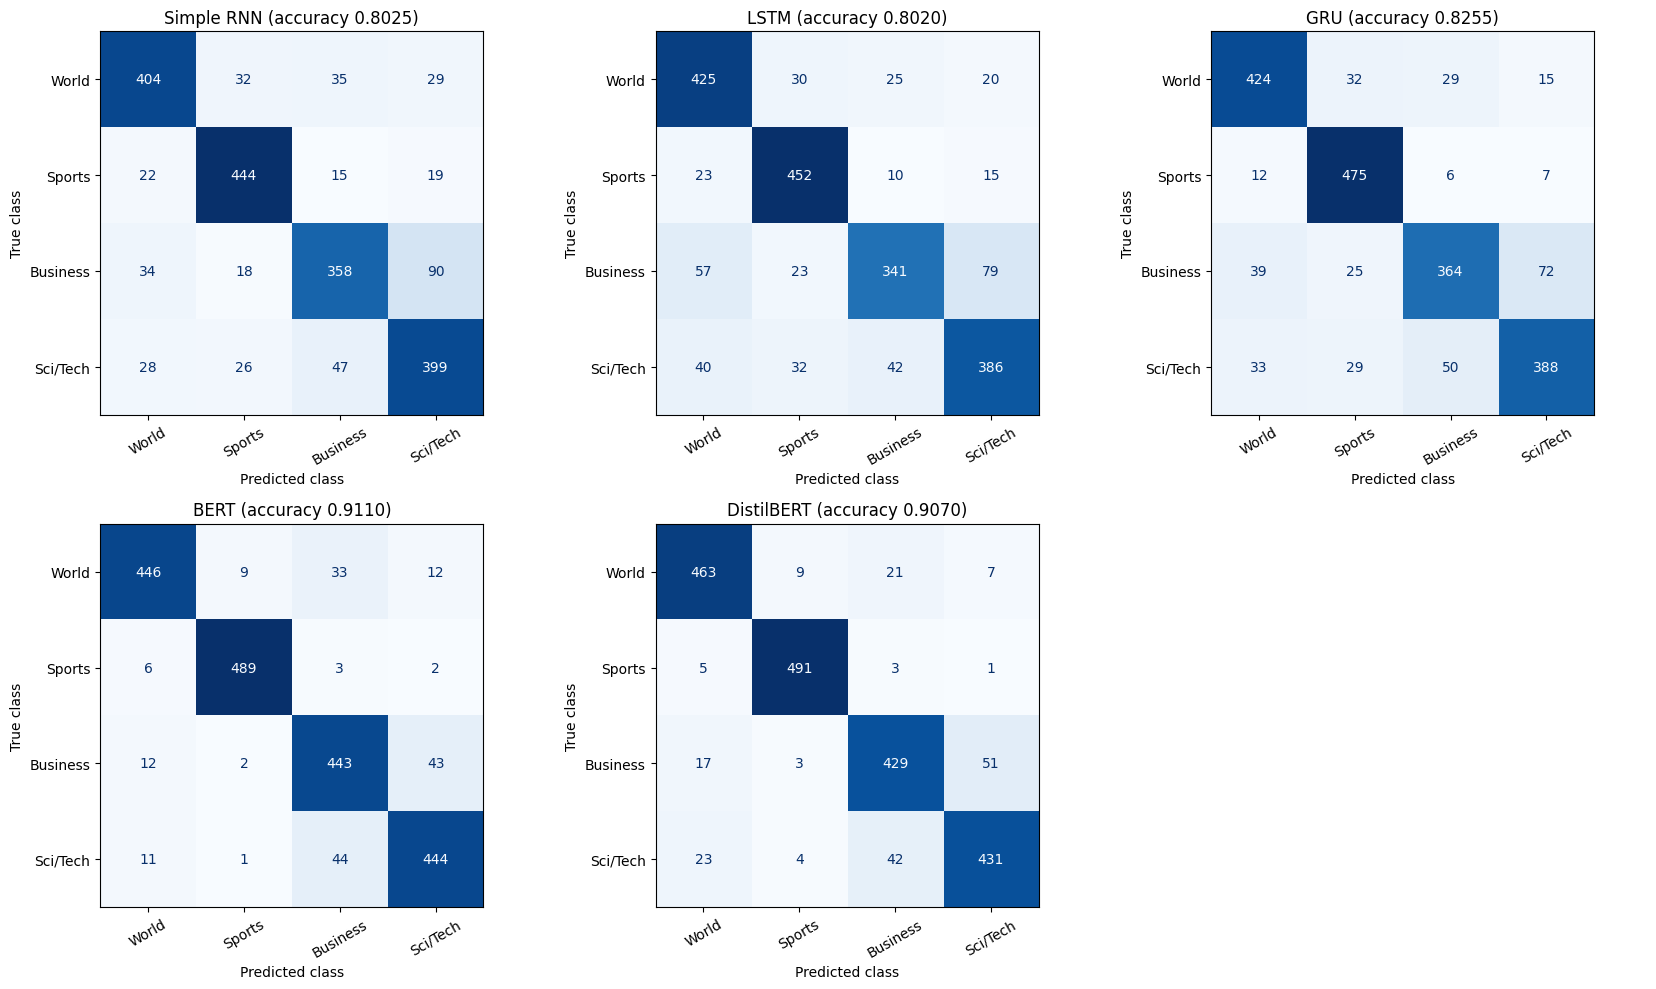

Automatic reading of the matrices:
- Simple RNN: most frequent mistake: true 'Business' predicted as 'Sci/Tech' (90 articles); weakest class: Business (recall 0.716)
- LSTM: most frequent mistake: true 'Business' predicted as 'Sci/Tech' (79 articles); weakest class: Business (recall 0.682)
- GRU: most frequent mistake: true 'Business' predicted as 'Sci/Tech' (72 articles); weakest class: Business (recall 0.728)
- BERT: most frequent mistake: true 'Sci/Tech' predicted as 'Business' (44 articles); weakest class: Business (recall 0.886)
- DistilBERT: most frequent mistake: true 'Business' predicted as 'Sci/Tech' (51 articles); weakest class: Business (recall 0.858)


In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
for ax, name in zip(axes.ravel(), MODEL_NAMES):
    cm = np.array(RESULTS[name]["confusion_matrix"])
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=30, values_format="d")
    ax.set_title(f"{name} (accuracy {RESULTS[name]['accuracy']:.4f})")
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

print("Automatic reading of the matrices:")
for name in MODEL_NAMES:
    cm = np.array(RESULTS[name]["confusion_matrix"])
    off_diag = cm.copy()
    np.fill_diagonal(off_diag, 0)
    recall_per_class = np.diag(cm) / cm.sum(axis=1)
    weakest = int(recall_per_class.argmin())
    if off_diag.max() == 0:
        mistake = "no mistakes"
    else:
        i, j = np.unravel_index(off_diag.argmax(), off_diag.shape)
        mistake = f"most frequent mistake: true '{CLASS_NAMES[i]}' predicted as '{CLASS_NAMES[j]}' ({off_diag[i, j]} articles)"
    print(f"- {name}: {mistake}; weakest class: {CLASS_NAMES[weakest]} (recall {recall_per_class[weakest]:.3f})")

## Section 13: Training Curves

- **Training loss** measures the error on the data the model learns from. It normally goes down.
- **Validation loss** measures the error on held-out data. If training loss keeps falling while validation loss starts to rise, the model is **overfitting** (memorising the training data).
- **Convergence** means the curves have levelled off. If they are still dropping at the final epoch, training more might help.
- All five models are trained for the same 5 epochs, so their curves can be compared point by point. The saved model is the one from the best validation epoch, so a late rise in validation loss does not hurt the test result.

**What this code does:** plots training and validation loss for each model, then validation accuracy for all models together, and prints an automatic reading of each curve (saved best epoch, train/validation gap, and whether validation loss rose after its minimum).

## Section 14: Final Model Comparison

**What this code does:** it collects the measured results of all five models into **one pandas DataFrame** (accuracy, macro precision, macro recall, macro F1, training time, inference time and parameter count), sorts it by **test accuracy**, saves it as a CSV file, and draws four bar charts. Accuracy and F1 charts use a zoomed y-axis so small differences are visible; read the values printed on the bars.

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1-score,Training Time (s),Inference Time (s),Number of Parameters
0,BERT,0.9110,0.9121,0.9110,0.9113,253.0,3.78,"109,485,316"
1,DistilBERT,0.9070,0.9065,0.9070,0.9067,132.2,1.89,"66,956,548"
2,GRU,0.8255,0.8243,0.8255,0.8235,8.8,0.09,"1,401,732"
3,Simple RNN,0.8025,0.8029,0.8025,0.8019,9.8,0.09,"1,269,636"
4,LSTM,0.8020,0.8023,0.8020,0.8000,8.9,0.09,"1,467,780"


Run mode: debug | parameters include embeddings and pretrained weights for every model.


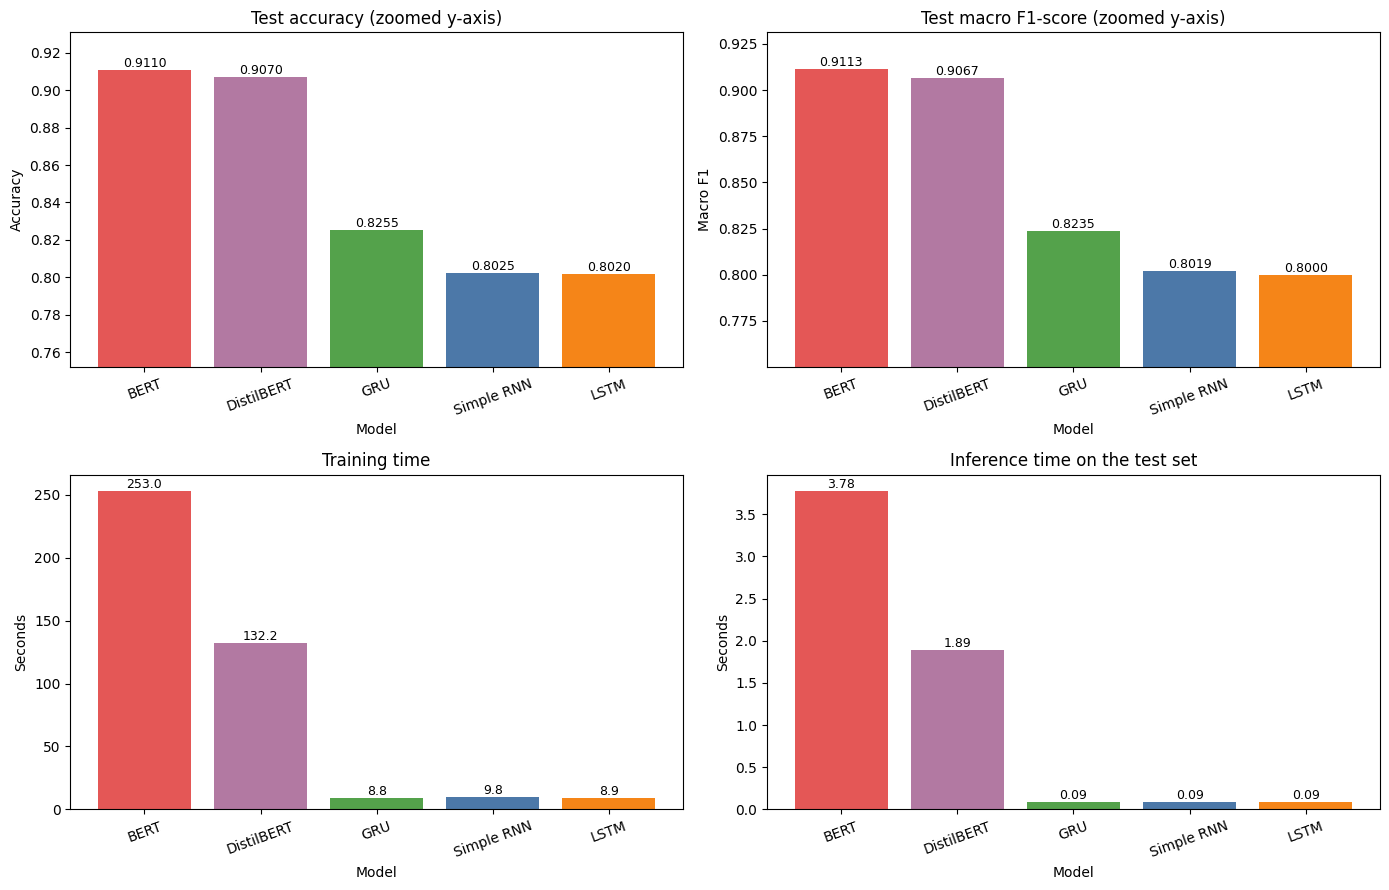

In [ ]:
rows = []
for name in MODEL_NAMES:
    r = RESULTS[name]
    rows.append({
        "Model": name,
        "Accuracy": r["accuracy"],
        "Macro Precision": r["macro_precision"],
        "Macro Recall": r["macro_recall"],
        "Macro F1-score": r["macro_f1"],
        "Training Time (s)": r["train_time_sec"],
        "Inference Time (s)": r["inference_time_sec"],
        "Number of Parameters": r["params_total"],
    })
final_df = pd.DataFrame(rows).sort_values("Accuracy", ascending=False).reset_index(drop=True)
final_df.to_csv(os.path.join(RESULTS_DIR, "final_comparison.csv"), index=False)

display(final_df.style.format({"Accuracy": "{:.4f}", "Macro Precision": "{:.4f}", "Macro Recall": "{:.4f}",
                               "Macro F1-score": "{:.4f}", "Training Time (s)": "{:.1f}",
                               "Inference Time (s)": "{:.2f}", "Number of Parameters": "{:,}"}))
print("Run mode:", RESULTS[MODEL_NAMES[0]]["run_mode"], "| parameters include embeddings and pretrained weights for every model.")

colors = ["#4C78A8", "#F58518", "#54A24B", "#E45756", "#B279A2"]
def bar_panel(ax, column, title, ylabel, zoom=False, fmt="{:.4f}"):
    values = final_df[column].values
    bars = ax.bar(final_df["Model"], values, color=[colors[MODEL_NAMES.index(m)] for m in final_df["Model"]])
    if zoom:
        ax.set_ylim(max(0, values.min() - 0.05), min(1.0, values.max() + 0.02))
    ax.set_title(title); ax.set_ylabel(ylabel); ax.set_xlabel("Model")
    ax.tick_params(axis="x", rotation=20)
    for b, v in zip(bars, values):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), fmt.format(v), ha="center", va="bottom", fontsize=9)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
bar_panel(axes[0, 0], "Accuracy", "Test accuracy (zoomed y-axis)", "Accuracy", zoom=True)
bar_panel(axes[0, 1], "Macro F1-score", "Test macro F1-score (zoomed y-axis)", "Macro F1", zoom=True)
bar_panel(axes[1, 0], "Training Time (s)", "Training time", "Seconds", fmt="{:.1f}")
bar_panel(axes[1, 1], "Inference Time (s)", "Inference time on the test set", "Seconds", fmt="{:.2f}")
plt.tight_layout()
plt.show()

## Section 15: Results and Discussion

The code cell below states the findings **from the measured table** (it changes whenever you re-run the notebook). The markdown after it lists possible explanations; treat them as **hypotheses to check against your numbers**, not as proven facts.

**What the code does:** it identifies the best model, compares the best recurrent model with the best Transformer, compares LSTM/GRU with the Simple RNN, compares DistilBERT with BERT, and relates accuracy to computational cost.

In [ ]:
def cmp_word(a, b):
    return "higher" if a > b else ("lower" if a < b else "equal")

get = lambda m: final_df[final_df["Model"] == m].iloc[0]
recurrent = final_df[final_df["Model"].isin(["Simple RNN", "LSTM", "GRU"])]
transformers_df = final_df[final_df["Model"].isin(["BERT", "DistilBERT"])]
best_overall = final_df.iloc[0]
best_rec, best_tr = recurrent.iloc[0], transformers_df.iloc[0]

print(f"1. Best model on the test set: {best_overall['Model']} (accuracy {best_overall['Accuracy']:.4f}, macro F1 {best_overall['Macro F1-score']:.4f}).")
gap_pp = (best_tr["Accuracy"] - best_rec["Accuracy"]) * 100
print(f"2. Best Transformer ({best_tr['Model']}) vs best recurrent model ({best_rec['Model']}): accuracy is {cmp_word(best_tr['Accuracy'], best_rec['Accuracy'])} "
      f"by {abs(gap_pp):.2f} percentage points.")
print(f"   Cost of that comparison: training time x{best_tr['Training Time (s)'] / best_rec['Training Time (s)']:.1f}, "
      f"inference time x{best_tr['Inference Time (s)'] / best_rec['Inference Time (s)']:.1f}, "
      f"parameters x{best_tr['Number of Parameters'] / best_rec['Number of Parameters']:.1f} (Transformer relative to recurrent).")
rnn_acc = get("Simple RNN")["Accuracy"]
for m in ["LSTM", "GRU"]:
    d = (get(m)["Accuracy"] - rnn_acc) * 100
    print(f"3. {m} accuracy is {cmp_word(get(m)['Accuracy'], rnn_acc)} than Simple RNN by {abs(d):.2f} percentage points.")
b, d_ = get("BERT"), get("DistilBERT")
print(f"4. DistilBERT vs BERT: accuracy {cmp_word(d_['Accuracy'], b['Accuracy'])} by {abs(d_['Accuracy'] - b['Accuracy']) * 100:.2f} percentage points; "
      f"training time x{d_['Training Time (s)'] / b['Training Time (s)']:.2f}, inference time x{d_['Inference Time (s)'] / b['Inference Time (s)']:.2f}, "
      f"parameters x{d_['Number of Parameters'] / b['Number of Parameters']:.2f} (DistilBERT relative to BERT).")
print("5. Ranking by accuracy per training-second (higher = cheaper accuracy):")
eff = final_df.assign(AccuracyPerTrainingSecond=final_df["Accuracy"] / final_df["Training Time (s)"]).sort_values("AccuracyPerTrainingSecond", ascending=False)
display(eff[["Model", "Accuracy", "Training Time (s)", "AccuracyPerTrainingSecond"]].round(5))
if RESULTS[MODEL_NAMES[0]]["run_mode"] == "debug":
    print("\nCAUTION: these numbers come from the small debug subset and are only a sanity check, not final findings.")
print("Reminder: one seed was used, so differences of a few tenths of a percentage point may be within random variation.")

1. Best model on the test set: BERT (accuracy 0.9110, macro F1 0.9113).
2. Best Transformer (BERT) vs best recurrent model (GRU): accuracy is higher by 8.55 percentage points.
   Cost of that comparison: training time x28.9, inference time x42.1, parameters x78.1 (Transformer relative to recurrent).
3. LSTM accuracy is lower than Simple RNN by 0.05 percentage points.
3. GRU accuracy is higher than Simple RNN by 2.30 percentage points.
4. DistilBERT vs BERT: accuracy lower by 0.40 percentage points; training time x0.52, inference time x0.50, parameters x0.61 (DistilBERT relative to BERT).
5. Ranking by accuracy per training-second (higher = cheaper accuracy):


,Model,Accuracy,Training Time (s),AccuracyPerTrainingSecond
2,GRU,0.8255,8.76821,0.09415
4,LSTM,0.8020,8.93902,0.08972
3,Simple RNN,0.8025,9.77444,0.08210
1,DistilBERT,0.9070,132.20725,0.00686
0,BERT,0.9110,252.98795,0.00360



CAUTION: these numbers come from the small debug subset and are only a sanity check, not final findings.
Reminder: one seed was used, so differences of a few tenths of a percentage point may be within random variation.


### 15.1 Possible reasons for the observed differences (hypotheses to compare with your table)
- **Pretraining vs training from scratch:** BERT and DistilBERT arrive with language knowledge learned from huge corpora; the recurrent models must learn word meanings from the AG News training set only. This is usually the biggest reason Transformers do better, especially when labelled data is limited.
- **Contextual representations:** attention lets every word be interpreted using the whole article; recurrent models compress the article into one final hidden vector, which can lose information.
- **Sub-word tokenization:** WordPiece handles rare or unseen words (names, product terms) by splitting them, whereas our word-level vocabulary maps them to `<unk>` (see the out-of-vocabulary rate in Section 5.3).
- **Gating:** LSTM and GRU gates make it easier to carry information across a sequence and make gradients flow better than in a Simple RNN, so they are often (not always) more accurate and more stable. On short news snippets the gap can be small.
- **Truncation:** recurrent models see at most `RNN_MAX_LEN` words; Transformers see up to `TR_MAX_LEN` tokens.
- **Distillation:** DistilBERT has fewer layers; if its accuracy is close to BERT's, this indicates that much of BERT's capacity is not needed for a four-class topic task.
- **Computational cost:** Transformers have far more parameters and their self-attention cost grows with the square of the sequence length, so they need more training and inference time and more GPU memory. The recurrent models' parameters are mostly the embedding table, and they are cheap to train. Whether the extra cost is worthwhile depends on how large the accuracy gain in the table above is.

### 15.2 Limitations that affect how far the comparison can be trusted
- **Different tokenizers:** the recurrent models use a simple word tokenizer and a 30k vocabulary; BERT and DistilBERT use their own WordPiece tokenizers, so the models do not see identical inputs.
- **Pretrained vs random weights:** the comparison mixes architecture and transfer learning. A fairer architecture-only test would train Transformers from scratch or give the recurrent models pretrained embeddings (for example GloVe).
- **Different optimisation settings:** all models use the same number of epochs (5), optimiser type and schedule type, but the learning rate (2e-3 vs 2e-5), batch size (64 vs 32) and precision (fp32 vs fp16) differ because recurrent models trained from scratch and fine-tuned Transformers need different values. Hyperparameters were set by common practice, not extensively tuned, and the test set was never used for tuning.
- **Single run:** one random seed; no confidence intervals.
- **Timing:** wall-clock times depend on hardware and on fp16 (Transformers) versus fp32 (recurrent models). Training time includes per-epoch validation.
- **Parameter counts:** include embeddings and pretrained weights for all models; they are not "effective" or "FLOPs" measures.

## Section 16: Conclusion

**What this code does:** it writes the summary of the experiment from the measured results (so it is always consistent with the table), including the best model, the cost trade-off and the answers to the research questions in Section 1.4.

In [ ]:
mode_text = "the full AG News dataset" if RESULTS[MODEL_NAMES[0]]["run_mode"] == "full" else "a small debug subset (not final)"
best = final_df.iloc[0]
rank_text = ", ".join(f"{r.Model} ({r.Accuracy:.4f})" for r in final_df.itertuples())

summary = f"""
### Experiment summary
Five models (Simple RNN, LSTM, GRU, BERT, DistilBERT) were trained on {mode_text}, using {RESULTS[MODEL_NAMES[0]]['n_train']:,} training, {RESULTS[MODEL_NAMES[0]]['n_val']:,} validation and {RESULTS[MODEL_NAMES[0]]['n_test']:,} test articles with identical splits.
Test accuracy ranking: {rank_text}.

### Best model
**{best['Model']}** achieved the highest test accuracy ({best['Accuracy']:.4f}) and macro F1-score ({best['Macro F1-score']:.4f}) among the models ranked by accuracy.
It needed {best['Training Time (s)']:.1f} s of training, {best['Inference Time (s)']:.2f} s to classify the test set and has {best['Number of Parameters']:,} parameters.

### Research questions
- **RQ1 (Transformers vs recurrent):** best Transformer accuracy = {transformers_df.iloc[0]['Accuracy']:.4f} ({transformers_df.iloc[0]['Model']}); best recurrent accuracy = {recurrent.iloc[0]['Accuracy']:.4f} ({recurrent.iloc[0]['Model']}).
- **RQ2 (gating):** Simple RNN {get('Simple RNN')['Accuracy']:.4f}, LSTM {get('LSTM')['Accuracy']:.4f}, GRU {get('GRU')['Accuracy']:.4f}.
- **RQ3 (cost):** see the training time, inference time and parameter columns of the comparison table; Section 15 reports the exact ratios.
- **RQ4 (DistilBERT vs BERT):** DistilBERT {get('DistilBERT')['Accuracy']:.4f} vs BERT {get('BERT')['Accuracy']:.4f} accuracy, with DistilBERT using {get('DistilBERT')['Number of Parameters'] / get('BERT')['Number of Parameters'] * 100:.0f}% of BERT's parameters.
"""
display(Markdown(summary))


### Experiment summary
Five models (Simple RNN, LSTM, GRU, BERT, DistilBERT) were trained on a small debug subset (not final), using 7,200 training, 800 validation and 2,000 test articles with identical splits.
Test accuracy ranking: BERT (0.9110), DistilBERT (0.9070), GRU (0.8255), Simple RNN (0.8025), LSTM (0.8020).

### Best model
**BERT** achieved the highest test accuracy (0.9110) and macro F1-score (0.9113) among the models ranked by accuracy.
It needed 253.0 s of training, 3.78 s to classify the test set and has 109,485,316 parameters.

### Research questions
- **RQ1 (Transformers vs recurrent):** best Transformer accuracy = 0.9110 (BERT); best recurrent accuracy = 0.8255 (GRU).
- **RQ2 (gating):** Simple RNN 0.8025, LSTM 0.8020, GRU 0.8255.
- **RQ3 (cost):** see the training time, inference time and parameter columns of the comparison table; Section 15 reports the exact ratios.
- **RQ4 (DistilBERT vs BERT):** DistilBERT 0.9070 vs BERT 0.9110 accuracy, with DistilBERT using 61% of BERT's parameters.


### Why the best model did best
Use Section 15.1 together with your table: connect the winner's advantage to the factors that apply (pretraining, contextual representations, sub-word tokenization, gating, distillation) and check them against the confusion matrices in Section 12, for example whether the gains come mainly from the Business vs Sci/Tech confusion. State only what your measured results support.

### Limitations
See Section 15.2: different tokenizers, pretrained versus randomly initialised weights, unequal training budgets, a single random seed, hardware- and precision-dependent timings, and (if you used it) a debug subset.

### Possible future improvements
- Repeat each experiment with several random seeds and report mean ± standard deviation.
- Tune hyperparameters on the validation set (learning rate, hidden size, dropout, number of epochs), using the test set only once at the end.
- Give the recurrent models pretrained word embeddings (GloVe or fastText) and try bidirectional layers or attention pooling for a fairer comparison.
- Train recurrent models with the same sub-word tokenizer as BERT, or compare with a Transformer trained from scratch.
- Measure inference with identical numeric precision (all fp32 or all fp16) and on CPU as well as GPU, and report memory use.
- Analyse misclassified articles (error analysis) and try larger models or other datasets with more classes.

## Section 17: References

- **AG News dataset (Hugging Face):** https://huggingface.co/datasets/fancyzhx/ag_news
- Zhang, X., Zhao, J., LeCun, Y. (2015). *Character-level Convolutional Networks for Text Classification* (source of AG News as a benchmark): https://arxiv.org/abs/1509.01626
- **PyTorch documentation:** https://pytorch.org/docs/stable/index.html
- **Hugging Face Transformers documentation:** https://huggingface.co/docs/transformers
- **Hugging Face Datasets documentation:** https://huggingface.co/docs/datasets
- **BERT:** Devlin et al. (2019). *BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding*: https://arxiv.org/abs/1810.04805
- **DistilBERT:** Sanh et al. (2019). *DistilBERT, a distilled version of BERT*: https://arxiv.org/abs/1910.01108
- **scikit-learn model evaluation (accuracy, precision, recall, F1, confusion matrix):** https://scikit-learn.org/stable/modules/model_evaluation.html
- **LSTM:** Hochreiter & Schmidhuber (1997), *Long Short-Term Memory*, Neural Computation 9(8).
- **GRU:** Cho et al. (2014). *Learning Phrase Representations using RNN Encoder–Decoder*: https://arxiv.org/abs/1406.1078